# TASK 4: Email Spam Detection with Machine Learning

**Organization:** Oasis Infobyte

## Objective
Develop a Natural Language Processing (NLP) classification system that distinguishes spam messages from legitimate messages using machine learning.

## Project workflow
1. Dataset collection and loading
2. Exploratory Data Analysis (EDA)
3. Text preprocessing and cleaning
4. TF-IDF feature extraction
5. Training and testing data split
6. Multinomial Naive Bayes and Logistic Regression
7. Evaluation using accuracy, precision, recall, F1-score, and confusion matrices
8. Model comparison and error analysis
9. WordCloud visualization and model saving

**Dataset:** UCI SMS Spam Collection

**Important note:** The selected public dataset contains SMS messages rather than email bodies. It is suitable for demonstrating the requested spam-classification workflow, but results should be described as SMS spam detection rather than claiming validation on real email data.

In [1]:

# Cell 2: Import libraries

import re
import string
import warnings
import zipfile
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

warnings.filterwarnings("ignore")

# Consistent visualization settings
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42

print("Libraries imported successfully.")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully.
Pandas version: 2.2.3
NumPy version: 2.1.3


dataset

In [2]:

# Cell 3: Download and load the UCI SMS Spam Collection

DATA_URL = (
    "https://archive.ics.uci.edu/static/public/228/"
    "sms+spam+collection.zip"
)

print("Downloading dataset from the UCI repository...")

with urlopen(DATA_URL, timeout=60) as response:
    zip_data = BytesIO(response.read())

with zipfile.ZipFile(zip_data) as archive:
    # Locate the original data file inside the ZIP archive
    data_file = next(
        name for name in archive.namelist()
        if name.endswith("SMSSpamCollection")
    )

    with archive.open(data_file) as file:
        df = pd.read_csv(
            file,
            sep="\t",
            header=None,
            names=["label", "message"],
            encoding="utf-8"
        )

print("\nDataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))



Dataset loaded successfully!
Dataset shape: (5572, 2)


,label,message
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."
5,spam,FreeMsg Hey there darling it's been 3 week's n...
6,ham,Even my brother is not like to speak with me. ...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...


Initial data inspection

In [3]:

# Cell 4: Inspect structure, data types, and missing values

print("=" * 55)
print("DATASET INFORMATION")
print("=" * 55)

print("\nShape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null counts:")
df.info()

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nExact duplicate rows:", df.duplicated().sum())

print("\nSample legitimate and spam messages:")
display(df.sample(min(8, len(df)), random_state=RANDOM_STATE))


DATASET INFORMATION

Shape: (5572, 2)

Column names:
['label', 'message']

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB

Missing values:


,Missing Values
label,0
message,0



Exact duplicate rows: 403

Sample legitimate and spam messages:


,label,message
3245,ham,Squeeeeeze!! This is christmas hug.. If u lik ...
944,ham,And also I've sorta blown him off a couple tim...
1044,ham,Mmm thats better now i got a roast down me! i...
2484,ham,Mm have some kanji dont eat anything heavy ok
812,ham,So there's a ring that comes with the guys cos...
2973,ham,Sary just need Tim in the bollox &it hurt him ...
2991,ham,"Love isn't a decision, it's a feeling. If we c..."
2942,ham,My supervisor find 4 me one lor i thk his stud...


Class distribution

CLASS DISTRIBUTION


,Message Count,Percentage (%)
label,,
ham,4825,86.59
spam,747,13.41


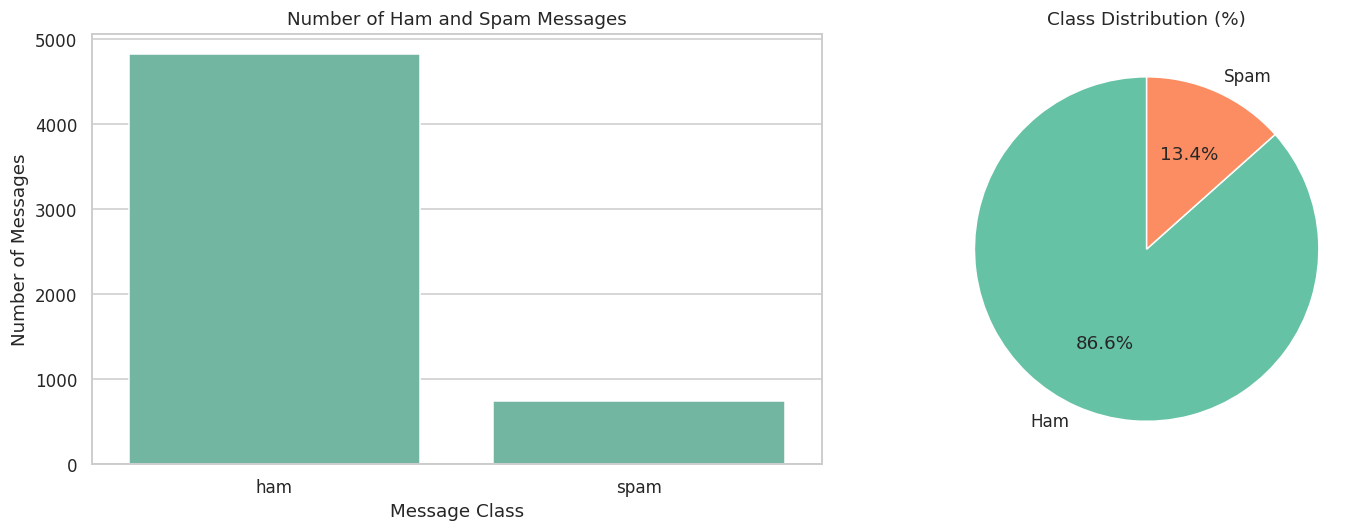

In [4]:

# Cell 5: Analyze spam versus ham distribution

class_counts = df["label"].value_counts()
class_percentages = df["label"].value_counts(normalize=True).mul(100)

class_summary = pd.DataFrame({
    "Message Count": class_counts,
    "Percentage (%)": class_percentages.round(2)
})

print("CLASS DISTRIBUTION")
display(class_summary)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=df,
    x="label",
    order=["ham", "spam"],
    ax=axes[0]
)
axes[0].set_title("Number of Ham and Spam Messages")
axes[0].set_xlabel("Message Class")
axes[0].set_ylabel("Number of Messages")

axes[1].pie(
    class_counts.reindex(["ham", "spam"]).values,
    labels=["Ham", "Spam"],
    autopct="%1.1f%%",
    startangle=90
)
axes[1].set_title("Class Distribution (%)")

plt.tight_layout()
plt.show()


Create useful text-based features

In [5]:

# Create text-based features for exploratory analysis

df["character_count"] = df["message"].str.len()

df["word_count"] = df["message"].apply(
    lambda text: len(text.split())
)

df["average_word_length"] = df["message"].apply(
    lambda text: (
        np.mean([len(word) for word in text.split()])
        if len(text.split()) > 0 else 0
    )
)

df["uppercase_count"] = df["message"].apply(
    lambda text: sum(1 for char in text if char.isupper())
)

df["digit_count"] = df["message"].apply(
    lambda text: sum(1 for char in text if char.isdigit())
)

print("Text features created successfully!")
display(df.head())


Text features created successfully!


,label,message,character_count,word_count,average_word_length,uppercase_count,digit_count
0,ham,"Go until jurong point, crazy.. Available only ...",111,20,4.600000,3,0
1,ham,Ok lar... Joking wif u oni...,29,6,4.000000,2,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155,28,4.571429,10,25
3,ham,U dun say so early hor... U c already then say...,49,11,3.545455,2,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",61,13,3.769231,2,0


Summary statistics by class

In [6]:

# Compare text statistics for ham and spam

feature_columns = [
    "character_count",
    "word_count",
    "average_word_length",
    "uppercase_count",
    "digit_count"
]

print("Text statistics grouped by message class:")
display(
    df.groupby("label")[feature_columns]
      .agg(["mean", "median", "min", "max"])
      .round(2)
)


Text statistics grouped by message class:


character_count                 word_count                  \
                 mean median min  max       mean median min  max   
label                                                              
ham             71.48   52.0   2  910      14.31   11.0   1  171   
spam           138.67  149.0  13  223      23.91   25.0   2   35   

      average_word_length                     uppercase_count                  \
                     mean median   min    max            mean median min  max   
label                                                                           
ham                  4.17   4.00  1.50  49.00            4.11    2.0   0  138   
spam                 4.97   4.85  3.33  17.33           15.47   14.0   0  128   

      digit_count                 
             mean median min max  
label                             
ham          0.31    0.0   0  23  
spam        15.81   16.0   0  47

Compare message lengths

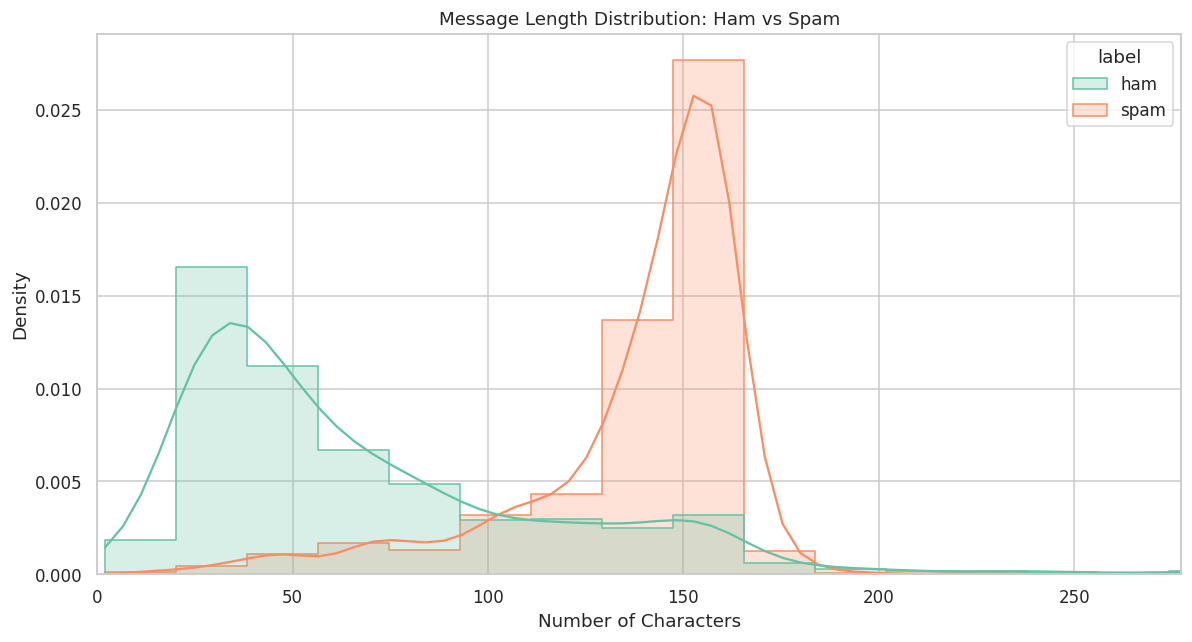

In [7]:

# Compare character counts for ham and spam

plt.figure(figsize=(11, 6))

sns.histplot(
    data=df,
    x="character_count",
    hue="label",
    bins=50,
    kde=True,
    element="step",
    stat="density",
    common_norm=False
)

plt.title("Message Length Distribution: Ham vs Spam")
plt.xlabel("Number of Characters")
plt.ylabel("Density")
plt.xlim(0, df["character_count"].quantile(0.99))
plt.tight_layout()
plt.show()


Compare word counts

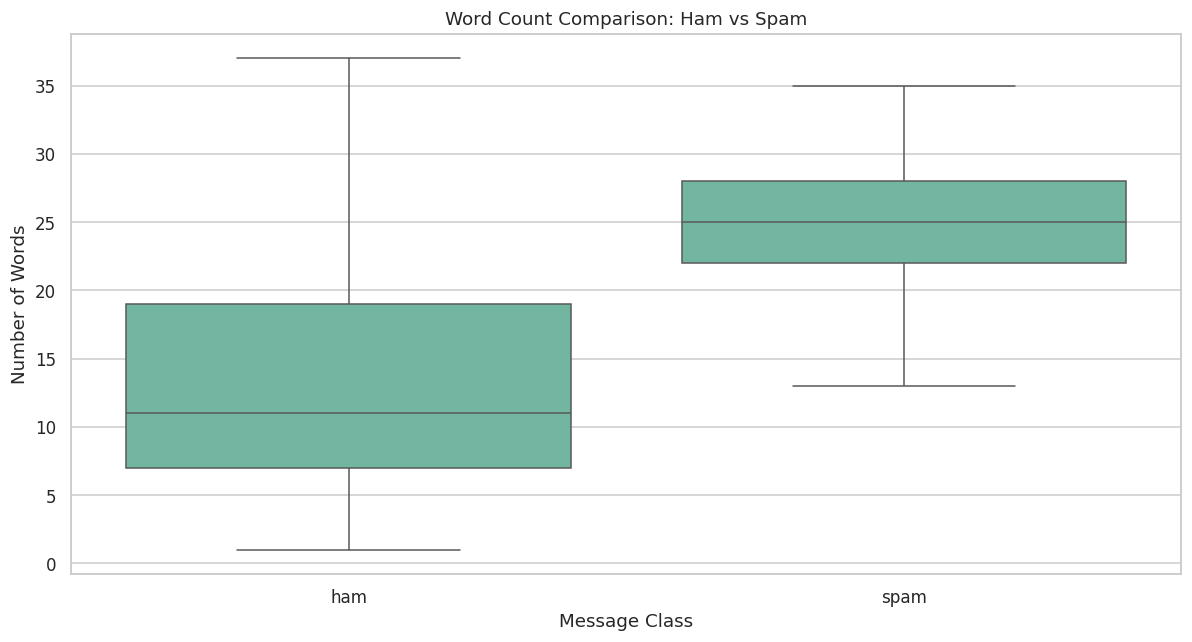

In [8]:

# Compare number of words in ham and spam messages

plt.figure(figsize=(11, 6))

sns.boxplot(
    data=df,
    x="label",
    y="word_count",
    order=["ham", "spam"],
    showfliers=False
)

plt.title("Word Count Comparison: Ham vs Spam")
plt.xlabel("Message Class")
plt.ylabel("Number of Words")
plt.tight_layout()
plt.show()


Explore uppercase letters and digits

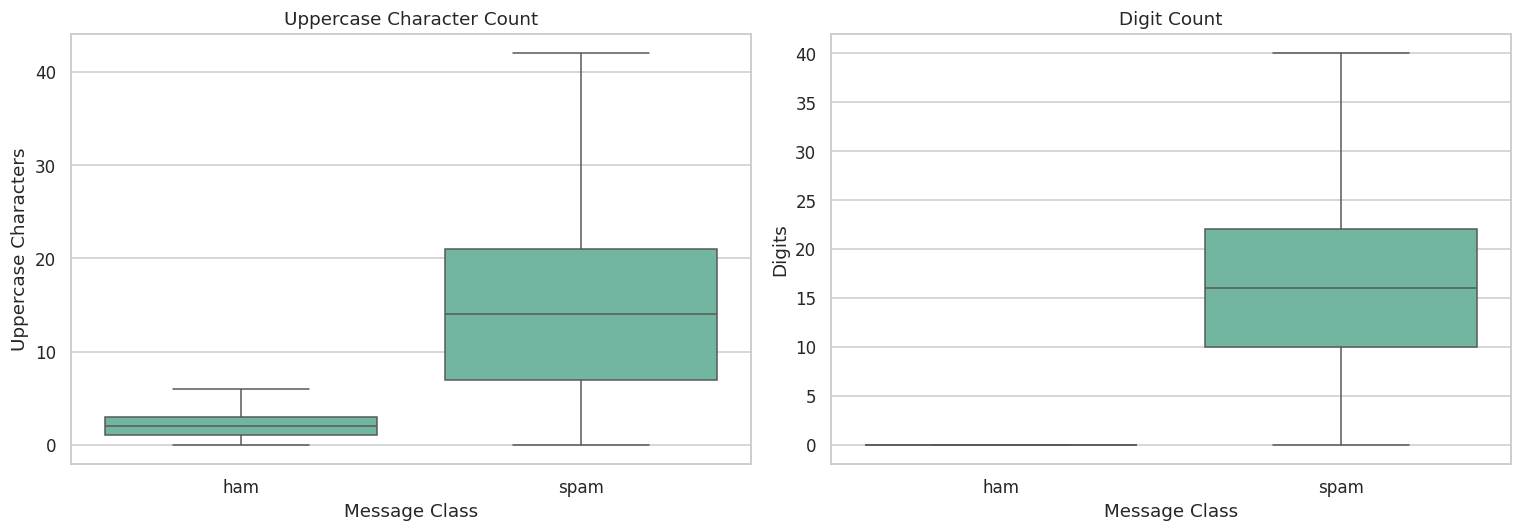

In [9]:

# Compare uppercase characters and digits across classes

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=df,
    x="label",
    y="uppercase_count",
    order=["ham", "spam"],
    showfliers=False,
    ax=axes[0]
)
axes[0].set_title("Uppercase Character Count")
axes[0].set_xlabel("Message Class")
axes[0].set_ylabel("Uppercase Characters")

sns.boxplot(
    data=df,
    x="label",
    y="digit_count",
    order=["ham", "spam"],
    showfliers=False,
    ax=axes[1]
)
axes[1].set_title("Digit Count")
axes[1].set_xlabel("Message Class")
axes[1].set_ylabel("Digits")

plt.tight_layout()
plt.show()


Investigate duplicate messages

In [10]:

# Investigate duplicate messages before removing them

duplicate_mask = df.duplicated(
    subset=["label", "message"],
    keep=False
)

print("Rows belonging to duplicate groups:", duplicate_mask.sum())

print("\nDuplicate rows by label:")
display(
    df.loc[duplicate_mask, "label"]
      .value_counts()
      .rename_axis("label")
      .to_frame("Rows in duplicate groups")
)

print("\nExamples of duplicated rows:")
display(
    df.loc[duplicate_mask, ["label", "message"]]
      .drop_duplicates()
      .head(10)
)

print("\nOriginal number of rows:", len(df))
print(
    "Rows after removing exact duplicates:",
    len(df.drop_duplicates(subset=["label", "message"]))
)


Rows belonging to duplicate groups: 684

Duplicate rows by label:


,Rows in duplicate groups
label,
ham,503
spam,181



Examples of duplicated rows:


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
7,ham,As per your request 'Melle Melle (Oru Minnamin...
8,spam,WINNER!! As a valued network customer you have...
9,spam,Had your mobile 11 months or more? U R entitle...
11,spam,"SIX chances to win CASH! From 100 to 20,000 po..."
12,spam,URGENT! You have won a 1 week FREE membership ...
45,ham,No calls..messages..missed calls
62,ham,Its a part of checking IQ
65,spam,"As a valued customer, I am pleased to advise y..."
66,ham,"Today is ""song dedicated day.."" Which song wil..."



Original number of rows: 5572
Rows after removing exact duplicates: 5169


Find the most frequent words

In [11]:

from collections import Counter

# Basic tokenization for exploratory word-frequency analysis

def get_basic_tokens(text):
    text = text.lower()
    return re.findall(r"\b[a-z]+\b", text)

ham_tokens = Counter(
    token
    for message in df.loc[df["label"] == "ham", "message"]
    for token in get_basic_tokens(message)
)

spam_tokens = Counter(
    token
    for message in df.loc[df["label"] == "spam", "message"]
    for token in get_basic_tokens(message)
)

print("Top 20 words in HAM messages:")
display(
    pd.DataFrame(
        ham_tokens.most_common(20),
        columns=["Word", "Frequency"]
    )
)

print("\nTop 20 words in SPAM messages:")
display(
    pd.DataFrame(
        spam_tokens.most_common(20),
        columns=["Word", "Frequency"]
    )
)


Top 20 words in HAM messages:


,Word,Frequency
0,i,2960
1,you,1948
2,to,1562
3,the,1133
4,a,1070
5,u,1033
6,and,858
7,in,823
8,me,777
9,my,754



Top 20 words in SPAM messages:


,Word,Frequency
0,to,691
1,a,380
2,call,355
3,you,297
4,your,264
5,free,224
6,the,206
7,for,204
8,now,199
9,or,188


Visualize frequent words

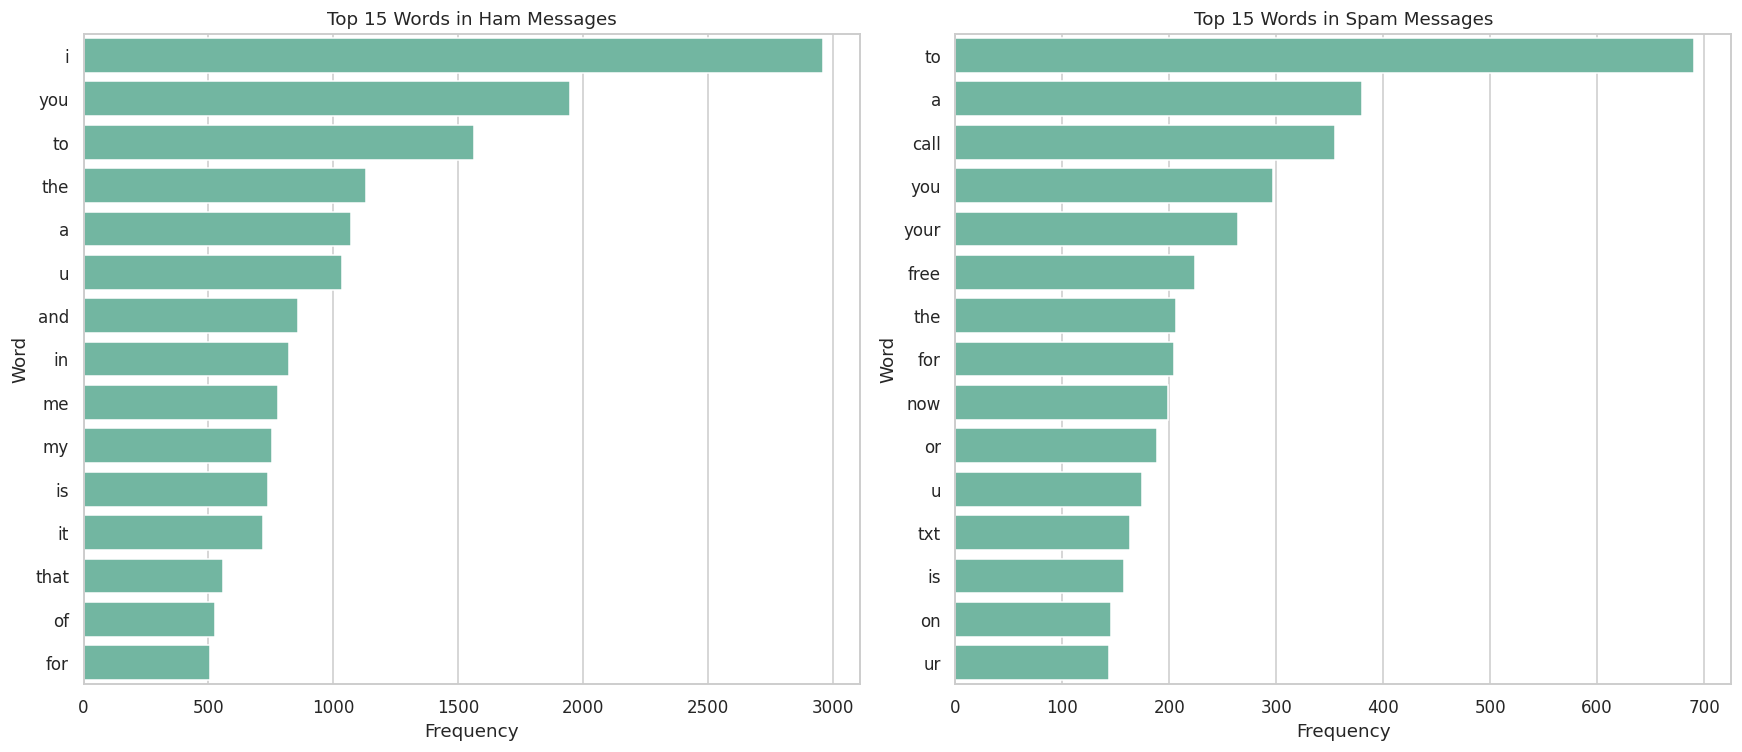

In [12]:

# Plot the most frequent words in ham and spam

ham_top = pd.DataFrame(
    ham_tokens.most_common(15),
    columns=["Word", "Frequency"]
)

spam_top = pd.DataFrame(
    spam_tokens.most_common(15),
    columns=["Word", "Frequency"]
)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.barplot(
    data=ham_top,
    x="Frequency",
    y="Word",
    ax=axes[0]
)
axes[0].set_title("Top 15 Words in Ham Messages")

sns.barplot(
    data=spam_top,
    x="Frequency",
    y="Word",
    ax=axes[1]
)
axes[1].set_title("Top 15 Words in Spam Messages")

plt.tight_layout()
plt.show()


Inspect example messages by class

In [13]:

# Read actual examples to understand the language used in each class

print("HAM MESSAGE EXAMPLES")
for message in df.loc[df["label"] == "ham", "message"].head(5):
    print("-", message)

print("\nSPAM MESSAGE EXAMPLES")
for message in df.loc[df["label"] == "spam", "message"].head(5):
    print("-", message)


HAM MESSAGE EXAMPLES
- Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...
- Ok lar... Joking wif u oni...
- U dun say so early hor... U c already then say...
- Nah I don't think he goes to usf, he lives around here though
- Even my brother is not like to speak with me. They treat me like aids patent.

SPAM MESSAGE EXAMPLES
- Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's apply 08452810075over18's
- FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to send, £1.50 to rcv
- WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code KL341. Valid 12 hours only.
- Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Update Co FREE on 0

Text preprocessing

In [14]:

# Create a cleaned text column for NLP

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_message"] = df["message"].apply(clean_text)

print("Text cleaning completed.")
display(df[["message", "clean_message", "label"]].head(10))


Text cleaning completed.


,message,clean_message,label
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ...",ham
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...,ham
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in 2 a wkly comp to win fa cup fina...,spam
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...,ham
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro...",ham
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it's been 3 week's n...,spam
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me. ...,ham
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request 'melle melle (oru minnamin...,ham
8,WINNER!! As a valued network customer you have...,winner!! as a valued network customer you have...,spam
9,Had your mobile 11 months or more? U R entitle...,had your mobile 11 months or more? u r entitle...,spam


Check the cleaned data

In [15]:

# Verify preprocessing and check for empty messages

print("Missing cleaned messages:", df["clean_message"].isna().sum())
print(
    "Empty cleaned messages:",
    df["clean_message"].str.len().eq(0).sum()
)

print("\nOriginal versus cleaned examples:")
display(df[["message", "clean_message"]].sample(8, random_state=42))


Missing cleaned messages: 0
Empty cleaned messages: 0

Original versus cleaned examples:


,message,clean_message
3245,Squeeeeeze!! This is christmas hug.. If u lik ...,squeeeeeze!! this is christmas hug.. if u lik ...
944,And also I've sorta blown him off a couple tim...,and also i've sorta blown him off a couple tim...
1044,Mmm thats better now i got a roast down me! i...,mmm thats better now i got a roast down me! i...
2484,Mm have some kanji dont eat anything heavy ok,mm have some kanji dont eat anything heavy ok
812,So there's a ring that comes with the guys cos...,so there's a ring that comes with the guys cos...
2973,Sary just need Tim in the bollox &it hurt him ...,sary just need tim in the bollox &it hurt him ...
2991,"Love isn't a decision, it's a feeling. If we c...","love isn't a decision, it's a feeling. if we c..."
2942,My supervisor find 4 me one lor i thk his stud...,my supervisor find 4 me one lor i thk his stud...


Prepare labels and split the data

In [16]:

# X contains the text; y contains the class label

X = df["clean_message"]
y = df["label"].map({"ham": 0, "spam": 1})

print("Feature count:", len(X))
print("\nTarget class counts:")
display(
    y.map({0: "ham", 1: "spam"})
     .value_counts()
     .rename_axis("Class")
     .to_frame("Count")
)

assert y.notna().all(), "Some labels were not converted correctly."
assert set(y.unique()) == {0, 1}, "Expected binary labels 0 and 1."

print("\nLabel mapping: ham = 0, spam = 1")


Feature count: 5572

Target class counts:


,Count
Class,
ham,4825
spam,747



Label mapping: ham = 0, spam = 1


Train/test split

In [17]:

from sklearn.model_selection import train_test_split

# Build a modeling dataset and remove exact duplicate label-message pairs

model_df = df[["label", "clean_message"]].drop_duplicates().copy()

X = model_df["clean_message"]
y = model_df["label"].map({"ham": 0, "spam": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Modeling rows after deduplication:", len(model_df))
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining class proportions:")
display(y_train.value_counts(normalize=True).rename("Proportion").to_frame())

print("\nTesting class proportions:")
display(y_test.value_counts(normalize=True).rename("Proportion").to_frame())


Modeling rows after deduplication: 5157
Training samples: 4125
Testing samples: 1032

Training class proportions:


,Proportion
label,
0,0.875394
1,0.124606



Testing class proportions:


,Proportion
label,
0,0.875969
1,0.124031


Convert text to TF-IDF features

In [18]:

from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    lowercase=False,       # Already lowercased in clean_text()
    ngram_range=(1, 2),    # Unigrams and bigrams
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("TF-IDF vectorization completed.")
print("Training matrix shape:", X_train_tfidf.shape)
print("Testing matrix shape:", X_test_tfidf.shape)
print("Vocabulary size:", len(tfidf.vocabulary_))


TF-IDF vectorization completed.
Training matrix shape: (4125, 10091)
Testing matrix shape: (1032, 10091)
Vocabulary size: 10091


Inspect a few TF-IDF features

In [19]:

# Inspect a small part of the TF-IDF matrix

feature_names = tfidf.get_feature_names_out()

tfidf_preview = pd.DataFrame(
    X_train_tfidf[:5].toarray(),
    columns=feature_names
)

print("TF-IDF feature matrix preview:")
display(tfidf_preview.iloc[:, :15])


TF-IDF feature matrix preview:


,00,00 sub,000,000 bonus,000 cash,000 prize,000 xmas,008704050406,008704050406 sp,02,02 06,02 09,0207,03,03 05
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


Model training

In [20]:

# Import classifiers and evaluation metrics

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Model and evaluation libraries imported successfully.")


Model and evaluation libraries imported successfully.


Train the Multinomial Naive Bayes model

In [21]:

# Initialize and train the Naive Bayes classifier

nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Multinomial Naive Bayes model trained successfully.")


Multinomial Naive Bayes model trained successfully.


Train the Logistic Regression model

In [22]:

# Initialize and train Logistic Regression

lr_model = LogisticRegression(
    max_iter=1000,
    random_state=RANDOM_STATE
)

lr_model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully.")


Logistic Regression model trained successfully.


Model evaluation

In [23]:

# Predict labels for the unseen test data

y_pred_nb = nb_model.predict(X_test_tfidf)
y_pred_lr = lr_model.predict(X_test_tfidf)

print("Predictions generated for both models.")
print("Test samples:", len(y_test))
print("Naive Bayes predictions:", len(y_pred_nb))
print("Logistic Regression predictions:", len(y_pred_lr))


Predictions generated for both models.
Test samples: 1032
Naive Bayes predictions: 1032
Logistic Regression predictions: 1032


Calculate evaluation metrics

In [24]:

# Evaluate both models using the same test set

def calculate_metrics(model_name, y_true, y_pred):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_true, y_pred, pos_label=1, zero_division=0
        ),
        "F1-Score": f1_score(
            y_true, y_pred, pos_label=1, zero_division=0
        )
    }

results = pd.DataFrame([
    calculate_metrics("Multinomial Naive Bayes", y_test, y_pred_nb),
    calculate_metrics("Logistic Regression", y_test, y_pred_lr)
])

print("MODEL PERFORMANCE COMPARISON")
display(
    results.style.format({
        "Accuracy": "{:.4f}",
        "Precision": "{:.4f}",
        "Recall": "{:.4f}",
        "F1-Score": "{:.4f}"
    })
)


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1-Score
0,Multinomial Naive Bayes,0.9632,1.0000,0.7031,0.8257
1,Logistic Regression,0.9651,1.0000,0.7188,0.8364


Detailed classification reports

In [25]:

# Show precision, recall, F1-score, and support for both classes

print("=" * 60)
print("MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_nb,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)

print("=" * 60)
print("LOGISTIC REGRESSION CLASSIFICATION REPORT")
print("=" * 60)

print(
    classification_report(
        y_test,
        y_pred_lr,
        labels=[0, 1],
        target_names=["Ham", "Spam"],
        zero_division=0
    )
)


MULTINOMIAL NAIVE BAYES CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.70      0.83       128

    accuracy                           0.96      1032
   macro avg       0.98      0.85      0.90      1032
weighted avg       0.96      0.96      0.96      1032

LOGISTIC REGRESSION CLASSIFICATION REPORT
              precision    recall  f1-score   support

         Ham       0.96      1.00      0.98       904
        Spam       1.00      0.72      0.84       128

    accuracy                           0.97      1032
   macro avg       0.98      0.86      0.91      1032
weighted avg       0.97      0.97      0.96      1032



Plot confusion matrices

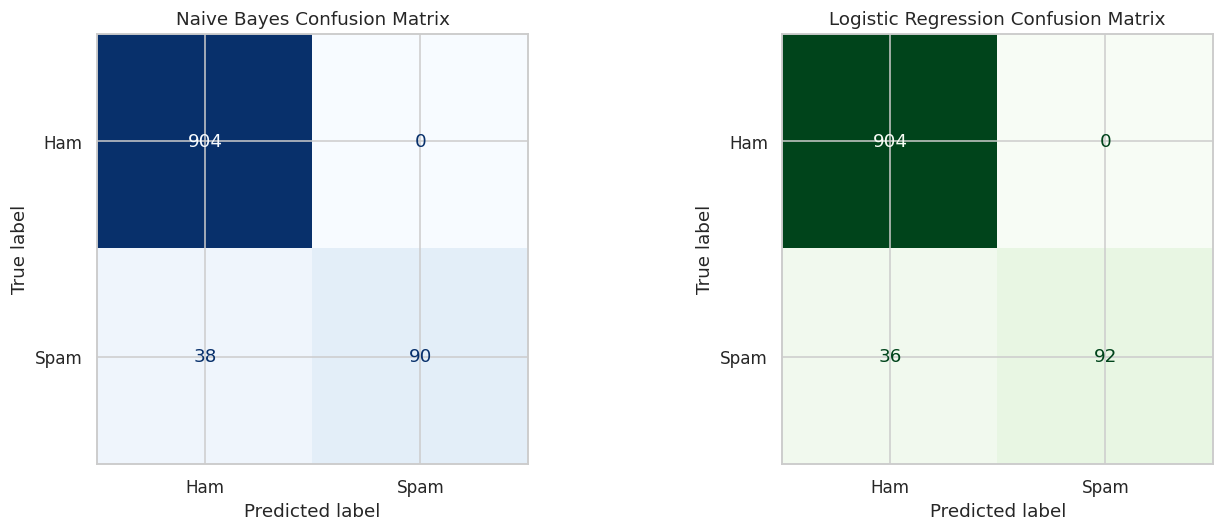

In [26]:

# Compare the types of classification errors made by each model

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_nb,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Blues",
    values_format="d",
    ax=axes[0],
    colorbar=False
)
axes[0].set_title("Naive Bayes Confusion Matrix")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    labels=[0, 1],
    display_labels=["Ham", "Spam"],
    cmap="Greens",
    values_format="d",
    ax=axes[1],
    colorbar=False
)
axes[1].set_title("Logistic Regression Confusion Matrix")

plt.tight_layout()
plt.show()


Compare model metrics visually

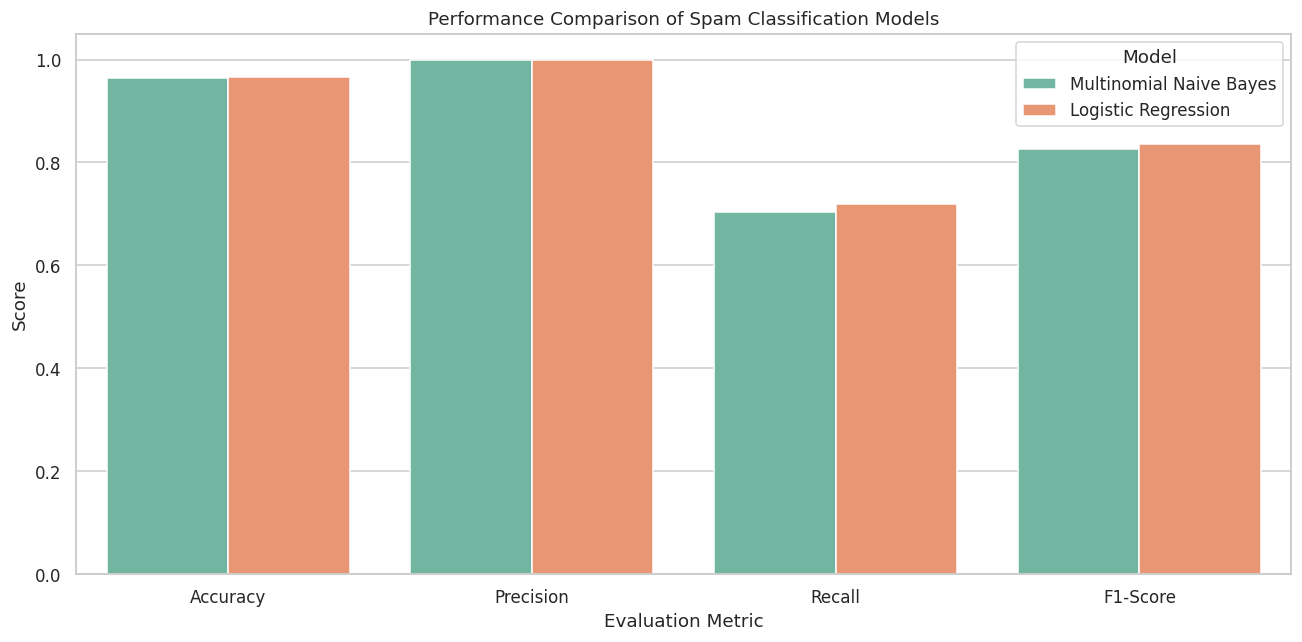

In [27]:

# Plot accuracy, precision, recall, and F1-score for both models

metrics_to_plot = ["Accuracy", "Precision", "Recall", "F1-Score"]

results_long = results.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_long,
    x="Metric",
    y="Score",
    hue="Model"
)

plt.title("Performance Comparison of Spam Classification Models")
plt.ylabel("Score")
plt.xlabel("Evaluation Metric")
plt.ylim(0, 1.05)
plt.legend(title="Model")
plt.tight_layout()
plt.show()


Identify the best model by spam F1-score

In [28]:

# Select the model with the highest spam F1-score

best_model_name = results.loc[
    results["F1-Score"].idxmax(), "Model"
]

if best_model_name == "Multinomial Naive Bayes":
    best_model = nb_model
    best_predictions = y_pred_nb
else:
    best_model = lr_model
    best_predictions = y_pred_lr

print("Best baseline model by spam F1-score:", best_model_name)

display(
    results.sort_values("F1-Score", ascending=False)
           .reset_index(drop=True)
)


Best baseline model by spam F1-score: Logistic Regression


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.965116,1.0,0.718750,0.836364
1,Multinomial Naive Bayes,0.963178,1.0,0.703125,0.825688


WordClouds

In [29]:

%pip -q install wordcloud


Generate ham and spam WordClouds

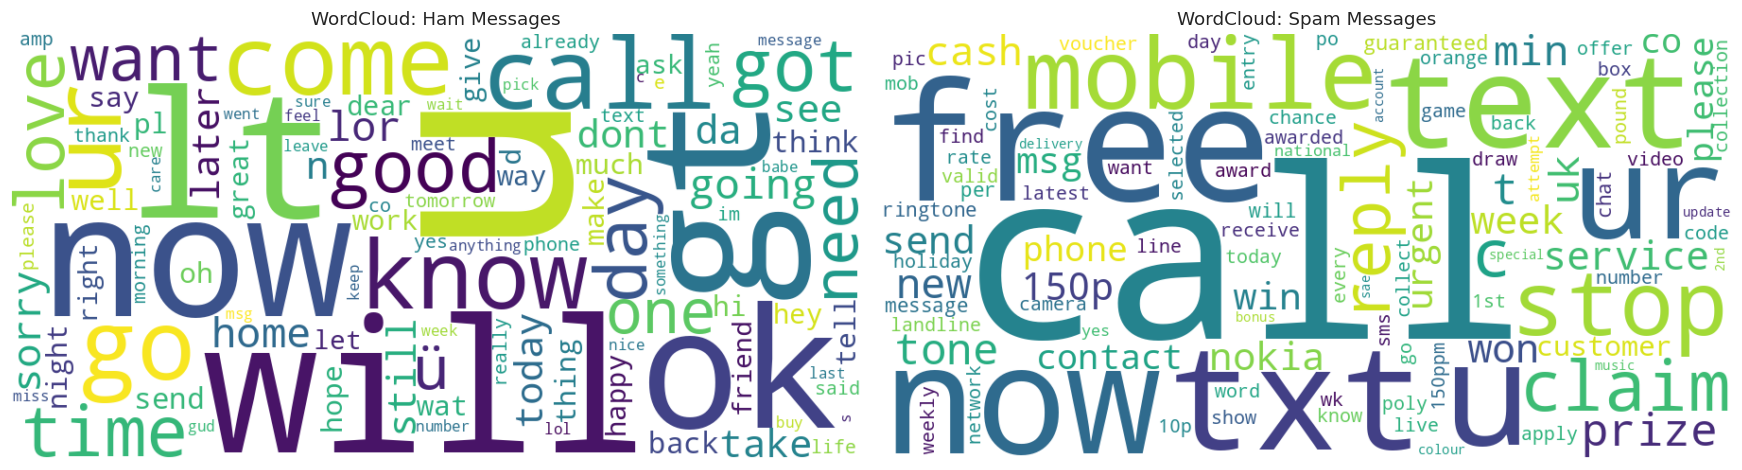

In [30]:

from wordcloud import WordCloud

ham_text = " ".join(
    df.loc[df["label"] == "ham", "clean_message"]
)

spam_text = " ".join(
    df.loc[df["label"] == "spam", "clean_message"]
)

ham_wordcloud = WordCloud(
    width=900,
    height=450,
    background_color="white",
    max_words=100,
    collocations=False
).generate(ham_text)

spam_wordcloud = WordCloud(
    width=900,
    height=450,
    background_color="white",
    max_words=100,
    collocations=False
).generate(spam_text)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

axes[0].imshow(ham_wordcloud, interpolation="bilinear")
axes[0].set_title("WordCloud: Ham Messages")
axes[0].axis("off")

axes[1].imshow(spam_wordcloud, interpolation="bilinear")
axes[1].set_title("WordCloud: Spam Messages")
axes[1].axis("off")

plt.tight_layout()
plt.show()


Inspect the misclassified messages

Error analysis

In [31]:

# Inspect spam messages that Logistic Regression missed

test_results = pd.DataFrame({
    "message": X_test,
    "actual": y_test,
    "predicted": y_pred_lr
})

# False negatives: actual spam predicted as ham
false_negatives = test_results[
    (test_results["actual"] == 1) &
    (test_results["predicted"] == 0)
]

# False positives: actual ham predicted as spam
false_positives = test_results[
    (test_results["actual"] == 0) &
    (test_results["predicted"] == 1)
]

print("False negatives (spam missed):", len(false_negatives))
print("False positives (ham flagged as spam):", len(false_positives))

print("\nExamples of spam messages missed:")
display(false_negatives[["message"]].head(10))

print("\nExamples of legitimate messages flagged as spam:")
display(false_positives[["message"]].head(10))


False negatives (spam missed): 36
False positives (ham flagged as spam): 0

Examples of spam messages missed:


,message
4725,free game. get rayman golf 4 free from the o2 ...
823,"smsservices. for yourinclusive text credits, p..."
1097,dear subscriber ur draw 4 £100 gift voucher wi...
3111,good luck! draw takes place 28th feb 06. good ...
1500,"sms. ac jsco: energy is high, but u may not kn..."
3360,sorry i missed your call let's talk when you h...
1069,someone u know has asked our dating service 2 ...
3639,customer service announcement. we recently tri...
3132,lookatme!: thanks for your purchase of a video...
2915,sorry! u can not unsubscribe yet. the mob offe...



Examples of legitimate messages flagged as spam:


,message


improving recall

Build the final pipeline

In [32]:

from sklearn.pipeline import Pipeline

# Combine TF-IDF preprocessing and Logistic Regression
# into one reusable model pipeline.

final_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        lowercase=False,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

# Train the complete pipeline using training text only.
final_model.fit(X_train, y_train)

print("Final NLP pipeline trained successfully.")


Final NLP pipeline trained successfully.


Test the pipeline with new messages

In [33]:

# Test the entire pipeline on new, manually written messages

sample_messages = [
    "Congratulations! You have won a free prize. Call now to claim.",
    "Hey, are we still meeting for lunch today?",
    "URGENT! Claim your cash reward by texting WIN to 80000."
]

predictions = final_model.predict(sample_messages)

for message, prediction in zip(sample_messages, predictions):
    label = "SPAM" if prediction == 1 else "HAM"

    print("Message:", message)
    print("Prediction:", label)
    print("-" * 70)


Message: Congratulations! You have won a free prize. Call now to claim.
Prediction: SPAM
----------------------------------------------------------------------
Message: Hey, are we still meeting for lunch today?
Prediction: HAM
----------------------------------------------------------------------
Message: URGENT! Claim your cash reward by texting WIN to 80000.
Prediction: HAM
----------------------------------------------------------------------


Save the model for Flask

In [34]:

import joblib
from pathlib import Path

MODEL_PATH = Path("/content/spam_classifier_pipeline.joblib")

joblib.dump(final_model, MODEL_PATH)

print("Model saved successfully!")
print("File path:", MODEL_PATH)
print("File size:", round(MODEL_PATH.stat().st_size / 1024, 2), "KB")


Model saved successfully!
File path: /content/spam_classifier_pipeline.joblib
File size: 294.3 KB


In [35]:

from google.colab import files

files.download("/content/spam_classifier_pipeline.joblib")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>